In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_colwidth", 150)
sns.set_theme(style="whitegrid")

print("Библиотеки успешно загружены")

Библиотеки успешно загружены


In [4]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/reviews.csv")

df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    encoding="utf-8"
)

print("Размер датасета:", df.shape)
print("Названия столбцов:", df.columns.tolist())

display(df.head())

Размер датасета: (90000, 2)
Названия столбцов: ['review', 'sentiment']


,review,sentiment
0,качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стои...,negative
1,"Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.",negative
2,"Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На кар...",negative
3,"товар не пришел, продавец продлил защиту без моего согласия. от продавца одни обещания",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


In [5]:
print("Количество отзывов:", len(df))
print("\nРаспределение классов:")
print(df["sentiment"].value_counts())

print("\nПропуски:")
print(df.isnull().sum())

Количество отзывов: 90000

Распределение классов:
sentiment
negative    30000
neautral    30000
positive    30000
Name: count, dtype: int64

Пропуски:
review       0
sentiment    0
dtype: int64


In [6]:
TEXT_COL = "review"
TARGET_COL = "sentiment"

In [7]:
print("Информация о датасете:")
df.info()

print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

print("\nПримеры значений по каждому столбцу:")
for column in df.columns:
    print(f"\n{column}:")
    print(df[column].head(5).tolist())

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     90000 non-null  str  
 1   sentiment  90000 non-null  str  
dtypes: str(2)
memory usage: 22.0 MB

Количество пропусков:
review       0
sentiment    0
dtype: int64

Количество дубликатов:
2250

Примеры значений по каждому столбцу:

review:
['качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стоит за такие деньги г.......', 'Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.', 'Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На картинке кажется приталенной на самом деле нет! Не рекомендую', 'товар не пришел, продавец продлил защиту без моего согласия. от продавца одни о

In [8]:
TEXT_COL = "review"
TARGET_COL = "sentiment"

df = df[[TEXT_COL, TARGET_COL]].copy()
df = df.dropna(subset=[TEXT_COL, TARGET_COL])

df[TEXT_COL] = df[TEXT_COL].astype(str)
df[TARGET_COL] = df[TARGET_COL].astype(str).str.strip()

print("Размер после удаления пропусков:", df.shape)
print("\nКоличество объектов каждого класса:")
print(df[TARGET_COL].value_counts())

print("\nПримеры отзывов:")
display(df.head())

Размер после удаления пропусков: (90000, 2)

Количество объектов каждого класса:
sentiment
negative    30000
neautral    30000
positive    30000
Name: count, dtype: int64

Примеры отзывов:


,review,sentiment
0,качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стои...,negative
1,"Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.",negative
2,"Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На кар...",negative
3,"товар не пришел, продавец продлил защиту без моего согласия. от продавца одни обещания",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


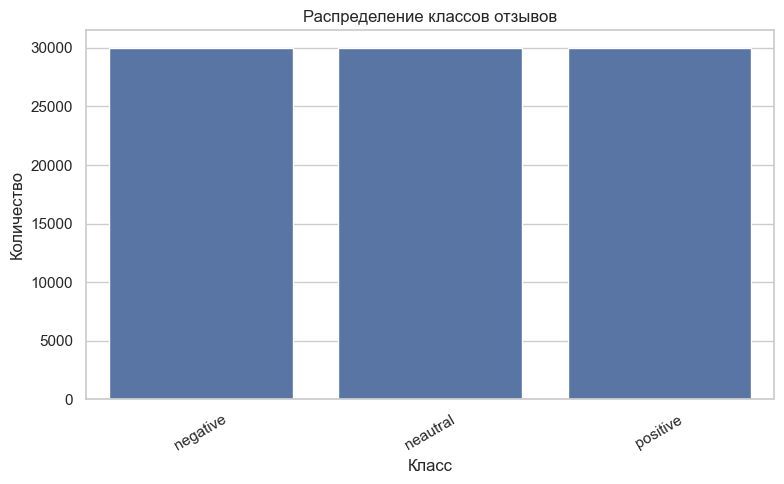

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=TARGET_COL,
    order=df[TARGET_COL].value_counts().index
)

plt.title("Распределение классов отзывов")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [10]:
import re
import string

RUSSIAN_STOP_WORDS = {
    "и", "а", "но", "или", "да", "в", "во", "на", "за",
    "к", "ко", "с", "со", "у", "о", "об", "от", "до",
    "по", "из", "для", "при", "над", "под", "не", "ни",
    "что", "это", "как", "так", "же", "бы", "ли", "то",
    "я", "мы", "ты", "вы", "он", "она", "оно", "они",
    "мне", "меня", "мной", "нам", "нас", "тебя", "ему",
    "ее", "её", "их", "им", "мой", "моя", "мое", "моё",
    "наш", "ваш", "свой", "который", "которая", "которые",
    "быть", "был", "была", "были", "есть", "будет",
    "очень", "уже", "еще", "ещё", "тоже", "только",
    "если", "когда", "где", "там", "тут", "здесь",
    "все", "всё", "всего", "всегда", "нет", "даже"
}

def clean_text(text):
    text = str(text).lower()

    # Удаляем ссылки
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Удаляем знаки пунктуации и цифры
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\d+", " ", text)

    # Оставляем только буквы русского и английского алфавитов
    text = re.sub(r"[^а-яёa-z\s]", " ", text)

    # Токенизация и удаление стоп-слов
    tokens = text.split()
    tokens = [
        word for word in tokens
        if word not in RUSSIAN_STOP_WORDS and len(word) > 1
    ]

    return " ".join(tokens)


examples = [
    "Этот товар ОЧЕНЬ хороший!!!",
    "Доставка заняла 15 дней, товар плохой.",
    "Не рекомендую покупать этот товар."
]

for example in examples:
    print("До:   ", example)
    print("После:", clean_text(example))
    print()

До:    Этот товар ОЧЕНЬ хороший!!!
После: этот товар хороший

До:    Доставка заняла 15 дней, товар плохой.
После: доставка заняла дней товар плохой

До:    Не рекомендую покупать этот товар.
После: рекомендую покупать этот товар



In [11]:
df["clean_text"] = df[TEXT_COL].apply(clean_text)

display(df[[TEXT_COL, "clean_text", TARGET_COL]].head(10))

,review,clean_text,sentiment
0,качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стои...,качество плохое пошив ужасный горловина наперекос фото соответствует ткань ужасная рисунок блеклый маленький рукав такой ужас стоит такие деньги,negative
1,"Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.",товар отдали другому человеку получила посылку ладно хоть деньги вернули,negative
2,"Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На кар...",ужасная синтетика тонкая ничего общего представленной картинкой яркая рисунок растянут тусклый впрочем сама кофта мешок картинке кажется приталенн...,negative
3,"товар не пришел, продавец продлил защиту без моего согласия. от продавца одни обещания",товар пришел продавец продлил защиту без моего согласия продавца одни обещания,negative
4,"Кофточка голая синтетика, носить не возможно.",кофточка голая синтетика носить возможно,negative
5,Очень глубокие проймы,глубокие проймы,negative
6,Я недовольна заказом.Я вот одного не понимаю почему внизу не прошито в остальных местах все прошито.Спасибо хоть за общительность и за быстрость.,недовольна заказом вот одного понимаю почему внизу прошито остальных местах прошито спасибо хоть общительность быстрость,negative
7,"заказала размер s на от 64,об 94,начнем с того, что влезть туда могут 3 меня, они постоянно сползают и заниматься вообще неудобно. качество ужасн...",заказала размер начнем того влезть туда могут постоянно сползают заниматься вообще неудобно качество ужасное будто просто одел капроновые колготки...,negative
8,"Заказ я сделала в июле. С тех пор посылка отслеживалась до границы с Россией(есть подозрение что ее там потеряли), а продавец отказывался возвраща...",заказ сделала июле тех пор посылка отслеживалась границы россией подозрение потеряли продавец отказывался возвращать оплату отправить повторно пос...,negative
9,Ужасное качество товара!,ужасное качество товара,negative


In [12]:
empty_count = (df["clean_text"].str.strip() == "").sum()

print("Пустых текстов после очистки:", empty_count)

Пустых текстов после очистки: 225


In [13]:
from sklearn.model_selection import train_test_split

X = df[TEXT_COL]
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape[0])
print("Тестовая выборка:", X_test.shape[0])

Обучающая выборка: 72000
Тестовая выборка: 18000


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            preprocessor=clean_text,
            min_df=2,
            max_df=0.95,
            ngram_range=(1, 2),
            sublinear_tf=True
        )
    ),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)

print("Модель успешно обучена")

Модель успешно обучена


In [15]:
tfidf = model.named_steps["tfidf"]

X_train_tfidf = tfidf.transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Размер обучающей TF-IDF матрицы:", X_train_tfidf.shape)
print("Размер тестовой TF-IDF матрицы:", X_test_tfidf.shape)
print("Размер словаря:", len(tfidf.vocabulary_))

Размер обучающей TF-IDF матрицы: (72000, 111233)
Размер тестовой TF-IDF матрицы: (18000, 111233)
Размер словаря: 111233


In [16]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy: {accuracy:.4f}")
print(f"F1-macro: {f1_macro:.4f}")

print("\nОтчёт классификации:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.7232
F1-macro: 0.7237

Отчёт классификации:
              precision    recall  f1-score   support

    neautral       0.60      0.67      0.63      6000
    negative       0.73      0.64      0.69      6000
    positive       0.84      0.86      0.85      6000

    accuracy                           0.72     18000
   macro avg       0.73      0.72      0.72     18000
weighted avg       0.73      0.72      0.72     18000



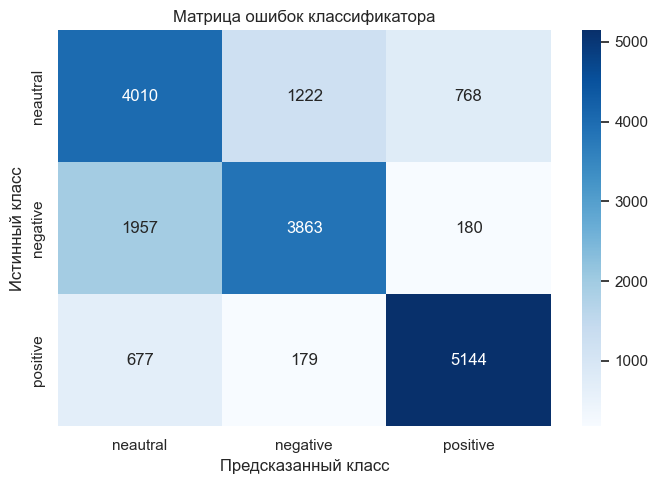

In [17]:
labels = model.classes_

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Матрица ошибок классификатора")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.tight_layout()
plt.show()

In [18]:
results = pd.DataFrame({
    "text": X_test.values,
    "clean_text": X_test.apply(clean_text).values,
    "true_label": y_test.values,
    "predicted_label": y_pred
})

errors = results[
    results["true_label"] != results["predicted_label"]
].copy()

print("Всего ошибочных предсказаний:", len(errors))

display(errors.head(5))

Всего ошибочных предсказаний: 4983


,text,clean_text,true_label,predicted_label
1,не пришло. деньги вернули,пришло деньги вернули,neautral,negative
2,Заказала в этом магазине платье и блузку. Но продавец прислал только блузку. Я писала сообщения продавцу несколько дней с вопросами где платье и к...,заказала этом магазине платье блузку продавец прислал блузку писала сообщения продавцу несколько дней вопросами платье получилось потому конца защ...,neautral,negative
3,"В жизни отличается,ткань тонкая,я бы не советовала,поэтому всего 2 звезды за быструю доставку.",жизни отличается ткань тонкая советовала поэтому звезды быструю доставку,negative,neautral
4,"Цвет не соответствует фото, это не жёлтый, а охра. Горловина, пройма просто оверложены, без подгиба. Тряпка тряпкой. Рассчитывала на другое качество.",цвет соответствует фото жёлтый охра горловина пройма просто оверложены без подгиба тряпка тряпкой рассчитывала другое качество,negative,neautral
9,"ткань не такая плотная как на фото ., аж просвечивает , ничего не утягивает ., забудьте , покупали жене , она её выкинула",ткань такая плотная фото аж просвечивает ничего утягивает забудьте покупали жене выкинула,negative,neautral


In [19]:
five_errors = errors.head(5).copy()

display(five_errors)

,text,clean_text,true_label,predicted_label
1,не пришло. деньги вернули,пришло деньги вернули,neautral,negative
2,Заказала в этом магазине платье и блузку. Но продавец прислал только блузку. Я писала сообщения продавцу несколько дней с вопросами где платье и к...,заказала этом магазине платье блузку продавец прислал блузку писала сообщения продавцу несколько дней вопросами платье получилось потому конца защ...,neautral,negative
3,"В жизни отличается,ткань тонкая,я бы не советовала,поэтому всего 2 звезды за быструю доставку.",жизни отличается ткань тонкая советовала поэтому звезды быструю доставку,negative,neautral
4,"Цвет не соответствует фото, это не жёлтый, а охра. Горловина, пройма просто оверложены, без подгиба. Тряпка тряпкой. Рассчитывала на другое качество.",цвет соответствует фото жёлтый охра горловина пройма просто оверложены без подгиба тряпка тряпкой рассчитывала другое качество,negative,neautral
9,"ткань не такая плотная как на фото ., аж просвечивает , ничего не утягивает ., забудьте , покупали жене , она её выкинула",ткань такая плотная фото аж просвечивает ничего утягивает забудьте покупали жене выкинула,negative,neautral


In [20]:
new_reviews = [
    "Отличный товар, качество полностью устраивает",
    "Очень плохое качество, деньги потрачены зря",
    "Не рекомендую, товар оказался ужасным"
]

predictions = model.predict(new_reviews)

for review, prediction in zip(new_reviews, predictions):
    print(f"Отзыв: {review}")
    print(f"Предсказанный класс: {prediction}")
    print()

Отзыв: Отличный товар, качество полностью устраивает
Предсказанный класс: positive

Отзыв: Очень плохое качество, деньги потрачены зря
Предсказанный класс: negative

Отзыв: Не рекомендую, товар оказался ужасным
Предсказанный класс: negative



## Выводы по практической работе № 6

**1. Датасет.**  
Для классификации текстов использован набор Russian-language reviews. В обработанном датасете осталось [количество] отзывов и [количество] классов.

**2. Предобработка.**  
Реализована функция очистки текста: приведение к нижнему регистру, удаление ссылок, пунктуации и цифр, токенизация и удаление стоп-слов. Отрицание «не» сохранено, поскольку оно влияет на смысл отзыва.

**3. Векторизация.**  
Для преобразования текстов в числовые признаки использован TF-IDF с параметрами `min_df=2`, `max_df=0.95` и `ngram_range=(1, 2)`. Размерность обучающей матрицы составила [N документов, M признаков].

**4. Классификатор.**  
Обучен классификатор Multinomial Naive Bayes. Разделение данных на обучающую и тестовую выборки выполнено в соотношении 80/20. Векторизатор обучался только на обучающей выборке.

**5. Оценка качества.**  
Accuracy составила [значение], F1-macro составил [значение]. По матрице ошибок определены основные типы неправильных предсказаний.

**6. Анализ ошибок.**  
Рассмотрено [количество] ошибочно классифицированных отзывов. Возможные причины ошибок: [перечислить причины, подтверждённые примерами].

**Заключение.**  
В ходе практической работы реализован полный базовый пайплайн классификации текстов: предобработка, TF-IDF-векторизация, обучение наивного байесовского классификатора и оценка качества. Результаты показывают [кратко описать качество модели и её ограничения].